# 05 · A newer language model for the features
**Report sections:** Model comparison (Q1), Open-ended improvement (Q5)

Notebook `04` showed that the hardest case is AI text that GPT-2 (2019) finds as unpredictable as human writing.
Ghostbuster (Verma et al., 2023) reports that features from a language model closer in quality to the generator
generalize better. So we recompute the same features with a newer small model and ask whether they help where it
matters: on kinds of AI text the classifier has not seen.

**Findings (numbers are in the tables below).**
- **Newer beats larger.** In the 3,500-text trial, `gpt2-medium` (3x the size of GPT-2, 2019) raised the unseen-kind
  score from 0.982 to 0.985; `SmolLM2-360M` (similar size, 2024) raised it to 0.988.
- **On the full data, SmolLM2 features improve every test.** Classifier alone, GPT-2 -> SmolLM2: validation
  0.989 -> 0.992, unseen domain 0.987 -> 0.989, unseen AI kind 0.982 -> 0.989.
- **The gain is where we aimed.** On the human-like kind of AI text (kind 0, unseen): 0.946 -> 0.971.
- **Using both models' features is about as good as SmolLM2 alone**: better on unseen domains (0.992 vs 0.989),
  slightly worse on unseen kinds (0.988 vs 0.989). The fixed rule from notebook `04` (best mean of the two) picks both,
  by 0.0008.
- **Blend with the SVM (weight 0.8):** validation 0.997, unseen domain 0.993, unseen kind 0.992, hardest kind 0.977
  (notebook-04 blend: 0.993 / 0.990 / 0.988 / 0.963).
- **Not yet known:** the Kaggle score of the new files.

In [1]:
# --- setup: make `src/` and this folder importable from anywhere ---
import sys, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks" / "joling"))
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import SEED, set_seed, RESULTS_DIR
from src.data import get_split, load_test
from src.models import make_model
from src.features import has_blank_line_breaks
from src.evaluate import auroc, predict_proba1, log_result, savefig, save_predictions, write_submission

from domain_eval import TopicDomains, domain_stress_test, mean_auroc_by_domain
from kind_eval import AIKinds, kind_stress_test, blend_unseen_kind, kind_weight_curve
from lm_features import FEATURES, load_cached
from repetition_features import RP_FEATURES, WORD_FEATURES, load_cached as load_repetition
from lm_model import SMOL_FEATURES, lm_linear_plus_trees, blend, blend_by_domain
from plots import plot_weight_curve

set_seed(SEED)
pd.set_option("display.width", 220)

## Data
The shared split, the saved SVM scores from notebooks `02` and `04`, and the same topic domains and AI kinds as
before (the kinds are still defined from GPT-2 features, so the tests are identical to notebook `04`).
The new features were made once with `python notebooks/joling/lm_onepass.py` (about 50 minutes) and are stored in
`results/joling_onepass_features_SmolLM2-360M.csv`.

In [3]:
train_df, val_df = get_split()
test_df = load_test()
y_tr, y_va = train_df["label"].to_numpy(), val_df["label"].to_numpy()

gpt2 = load_cached().join(load_repetition().drop(columns="file"))
val_scores = pd.read_csv(RESULTS_DIR / "joling_scores_val.csv")
train_unseen = pd.read_csv(RESULTS_DIR / "joling_scores_train_unseen.csv")
S = val_scores[val_scores.model == "svm"].set_index("id").loc[val_df["id"]]
S_tr = train_unseen[train_unseen.model == "svm"].set_index("id").loc[train_df["id"]]
K_all = pd.read_csv(RESULTS_DIR / "joling_scores_val_unseen_kind.csv")
K_svm = K_all[K_all.model == "svm (robust_svm_tuned)"].set_index("id").loc[val_df["id"]].reset_index()

domains = TopicDomains(k=8).fit(train_df["text"])
dom_tr, dom_va = domains.predict(train_df["text"]), domains.predict(val_df["text"])
KIND_FEATURES = FEATURES + RP_FEATURES
kinds = AIKinds(k=4).fit(gpt2.loc[train_df["id"][y_tr == 1], KIND_FEATURES])
kind_tr = kinds.assign(gpt2.loc[train_df["id"], KIND_FEATURES], y_tr)
kind_va = kinds.assign(gpt2.loc[val_df["id"], KIND_FEATURES], y_va)
assert (dom_va == S["domain"].to_numpy()).all() and (kind_va == K_svm["kind"].to_numpy()).all()   # same tests as notebook 04

[train] raw=10000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=10000 (clean=True)
split: train=8000 (AI=0.500)  val=2000 (AI=0.500)  quick=False clean=True


[test] raw=3000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=3000 (clean=True)


## Step 1 · A cheap trial before the expensive run
Scoring all 16,000 texts with a 360M-parameter model takes about 50 minutes on this laptop, so we first tried two
candidates on 3,500 texts (1,500 training rows + the validation set), with the notebook-04 classifier:
`gpt2-medium` (same family as GPT-2, three times larger, 2019) and `SmolLM2-360M` (similar size, 2024).

In [4]:
trial = pd.read_csv(RESULTS_DIR / "joling_new_lm_trial.csv", index_col=0)
trial.round(4)

,val,unseen domain,unseen AI kind,kind 0,kind 1,kind 2,kind 3
GPT-2 small (current),0.9862,0.9838,0.9823,0.9450,0.9997,0.9940,0.9907
SmolLM2-360M only,0.9900,0.9869,0.9879,0.9635,0.9993,0.9989,0.9897
GPT-2 small + SmolLM2-360M,0.9915,0.9888,0.9878,0.9604,0.9995,0.9987,0.9925
gpt2-medium only,0.9886,0.9871,0.9853,0.9531,0.9988,0.9979,0.9915
GPT-2 small + gpt2-medium,0.9890,0.9870,0.9861,0.9538,0.9998,0.9983,0.9923


The newer model helped more than the larger one, most of all on kind 0 (the human-like AI text), so SmolLM2-360M was
run on everything.

## Step 2 · Full data: GPT-2 features, SmolLM2 features, or both?
Same classifier as notebook `04` (logistic regression + bagged trees, held fixed), three feature sets.
The 19 word-count features do not depend on a language model and are in every set.

In [5]:
SETS = {
    "GPT-2 (54) = notebook 04": FEATURES + RP_FEATURES + WORD_FEATURES,
    "SmolLM2 (52)": SMOL_FEATURES + WORD_FEATURES,
    "GPT-2 + SmolLM2 (87)": FEATURES + RP_FEATURES + WORD_FEATURES + SMOL_FEATURES,
}
make = {name: (lambda cols=cols: lm_linear_plus_trees(columns=cols)) for name, cols in SETS.items()}

rows, dom_val, dom_train, kind_val, kind_tables = [], {}, {}, {}, {}
for name in SETS:
    t0 = time.time()
    dsum, _, preds = domain_stress_test(make[name], train_df, val_df, dom_tr, dom_va, verbose=False, score_train=True)
    dom_train[name] = preds.attrs.pop("train_unseen")
    dom_val[name] = preds
    ksum, kind_tables[name], kind_val[name] = kind_stress_test(make[name], train_df, val_df, kind_tr, kind_va, verbose=False)
    train_auc = auroc(y_tr, predict_proba1(make[name]().fit(train_df["text"], y_tr), train_df["text"]))
    rows.append({"features": name, "n_features": len(SETS[name]), "train_auroc": train_auc,
                 "val_auroc": dsum["val_layout_removed"], "unseen_domain": dsum["unseen_layout_removed_mean"],
                 "unseen_ai_kind": ksum["unseen_kind_mean"], "hardest_unseen_kind": ksum["hardest_unseen_kind"],
                 "seconds": round(time.time() - t0)})
    print(f"{name}: {rows[-1]['seconds']}s")
compare = pd.DataFrame(rows)
compare["mean_of_unseen_tests"] = (compare["unseen_domain"] + compare["unseen_ai_kind"]) / 2
compare.to_csv(RESULTS_DIR / "joling_new_lm_compare.csv", index=False)
pd.concat([p.assign(model=m) for m, p in kind_val.items()]).to_csv(RESULTS_DIR / "joling_scores_val_unseen_kind_05.csv", index=False)

CHOSEN = compare.sort_values("mean_of_unseen_tests").iloc[-1]["features"]     # same rule as notebook 04
print("chosen feature set:", CHOSEN)
compare.round(4)

GPT-2 (54) = notebook 04: 60s


SmolLM2 (52): 55s


GPT-2 + SmolLM2 (87): 64s
chosen feature set: GPT-2 + SmolLM2 (87)


,features,n_features,train_auroc,val_auroc,unseen_domain,unseen_ai_kind,hardest_unseen_kind,seconds,mean_of_unseen_tests
0,GPT-2 (54) = notebook 04,54,0.9941,0.9890,0.9871,0.9818,0.9461,60,0.9844
1,SmolLM2 (52),52,0.9960,0.9919,0.9889,0.9891,0.9713,55,0.9890
2,GPT-2 + SmolLM2 (87),87,0.9975,0.9936,0.9915,0.9881,0.9658,64,0.9898


In [6]:
# Unseen-kind AUROC for each kind: where does the newer model help?
by_kind = pd.concat({m: t.set_index("kind")["unseen"] for m, t in kind_tables.items()}, axis=1).T
by_kind.columns = [f"unseen: kind {c}" for c in by_kind.columns]
by_kind.round(4)

,unseen: kind 0,unseen: kind 1,unseen: kind 2,unseen: kind 3
GPT-2 (54) = notebook 04,0.9461,0.9988,0.9967,0.9855
SmolLM2 (52),0.9713,0.9977,0.9998,0.9874
GPT-2 + SmolLM2 (87),0.9658,0.9977,0.9996,0.9895


## Step 3 · Blend weight (training rows only) and the blend
Same procedure as notebook `04`: the weight with the best mean of the unseen-domain and unseen-kind curves.

kind curve: 203s
chosen weight of the classifier: 0.8


,lm_weight,unseen_domain,unseen_ai_kind,mean_of_both,hardest_kind
0,0.0,0.9340,0.9472,0.9406,0.9179
1,0.1,0.9475,0.9593,0.9534,0.9353
2,0.2,0.9595,0.9690,0.9643,0.9510
3,0.3,0.9699,0.9767,0.9733,0.9626
4,0.4,0.9785,0.9825,0.9805,0.9688
5,0.5,0.9848,0.9865,0.9857,0.9728
6,0.6,0.9892,0.9890,0.9891,0.9748
7,0.7,0.9917,0.9903,0.9910,0.9750
8,0.8,0.9930,0.9907,0.9919,0.9736
9,0.9,0.9932,0.9902,0.9917,0.9706


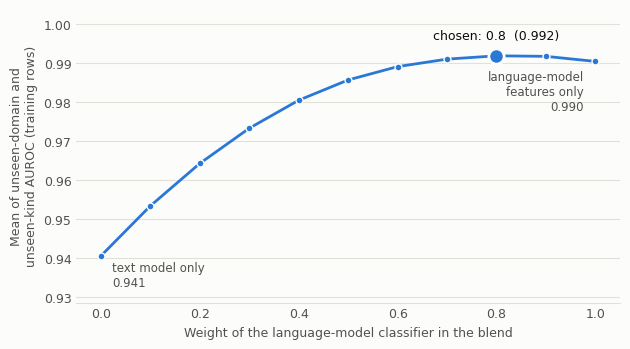

In [7]:
weights = np.round(np.arange(0, 1.01, 0.1), 1)
L_tr = dom_train[CHOSEN]
dom_curve = np.array([mean_auroc_by_domain(y_tr, blend_by_domain(S_tr["p_unseen_layout_removed"], L_tr["p_unseen"], dom_tr, w), dom_tr)
                      for w in weights])
t0 = time.time()
kc = kind_weight_curve(lambda: make_model("robust_svm_tuned"), make[CHOSEN], train_df, kind_tr, weights, verbose=False)
print(f"kind curve: {time.time() - t0:.0f}s")
kind_curve = kc[[float(w) for w in weights]].mean().to_numpy()
curves = pd.DataFrame({"lm_weight": weights, "unseen_domain": dom_curve, "unseen_ai_kind": kind_curve,
                       "mean_of_both": (dom_curve + kind_curve) / 2,
                       "hardest_kind": kc.groupby("kind")[[float(w) for w in weights]].mean().min().to_numpy()})
curves.to_csv(RESULTS_DIR / "joling_blend_weights_05.csv", index=False)
W = float(weights[int(np.argmax(curves["mean_of_both"]))])
print("chosen weight of the classifier:", W)
fig = plot_weight_curve(weights, curves["mean_of_both"], W)
fig.axes[0].set_ylabel("Mean of unseen-domain and\nunseen-kind AUROC (training rows)")
savefig(fig, "joling_blend_weight_05")
curves.round(4)

In [8]:
def blank_push(p, texts, push=0.1):
    b = np.array([has_blank_line_breaks(t) for t in texts], dtype=float)
    return (np.asarray(p) + push * b) / (1 + push)


def blend_numbers(name, w):
    Lv = dom_val[name]
    per_kind = blend_unseen_kind(K_svm, kind_val[name], w)
    return {"val_auroc": auroc(y_va, blend(S["p_layout_removed"], Lv["p_layout_removed"], w)),
            "unseen_domain": mean_auroc_by_domain(y_va, blend_by_domain(S["p_unseen_layout_removed"], Lv["p_unseen_layout_removed"], dom_va, w), dom_va),
            "unseen_ai_kind": float(per_kind.mean()), "hardest_unseen_kind": float(per_kind.min())}


W04 = float(pd.read_csv(RESULTS_DIR / "joling_blend_weights_04.csv").sort_values("mean_of_both").iloc[-1]["lm_weight"])
svm_kind = [auroc(y_va[(kind_va == c) | (y_va == 0)], K_svm[f"p_without_kind{c}"][(kind_va == c) | (y_va == 0)]) for c in range(kinds.k)]
blends = pd.DataFrame({
    "svm alone": {"val_auroc": auroc(y_va, S["p_layout_removed"]), "unseen_domain": mean_auroc_by_domain(y_va, S["p_unseen_layout_removed"], dom_va),
                  "unseen_ai_kind": float(np.mean(svm_kind)), "hardest_unseen_kind": float(np.min(svm_kind))},
    f"04 blend: svm + GPT-2 classifier (w={W04})": blend_numbers("GPT-2 (54) = notebook 04", W04),
    f"05 blend: svm + chosen classifier (w={W})": blend_numbers(CHOSEN, W),
}).T.rename_axis("model").reset_index()
blends.to_csv(RESULTS_DIR / "joling_blend_05.csv", index=False)
for _, r in blends.iterrows():
    log_result("joling_blend_05_log", {"model": r["model"], "features": CHOSEN, "lm_weight": W, "seed": SEED},
               {c: r[c] for c in ["val_auroc", "unseen_domain", "unseen_ai_kind", "hardest_unseen_kind"]})
blends.round(4)

,model,val_auroc,unseen_domain,unseen_ai_kind,hardest_unseen_kind
0,svm alone,0.9786,0.9328,0.9612,0.9321
1,04 blend: svm + GPT-2 classifier (w=0.8),0.9933,0.9900,0.9877,0.9630
2,05 blend: svm + chosen classifier (w=0.8),0.9965,0.9933,0.9920,0.9767


## Step 4 · Train on all 10,000 labelled rows and write the Kaggle files

In [9]:
full_df = pd.concat([train_df, val_df], ignore_index=True)
lm_all = make[CHOSEN]().fit(full_df["text"], full_df["label"])
svm_all = make_model("robust_svm_tuned").fit(full_df["text"], full_df["label"])
t_lm, t_svm = predict_proba1(lm_all, test_df["text"]), predict_proba1(svm_all, test_df["text"])
t_blend_blank = blend(blank_push(t_svm, test_df["text"]), t_lm, W)

Lv = dom_val[CHOSEN]
save_predictions("joling_lm_05", val_df, Lv["p_standard"], test_df, t_lm)
save_predictions("joling_blend_05_blank", val_df, blend(blank_push(S["p_standard"], val_df["text"]), Lv["p_standard"], W), test_df, t_blend_blank)
write_submission(test_df, t_lm, tag="joling_lm_05")
write_submission(test_df, t_blend_blank, tag="joling_blend_05_blank");

saved results/preds_joling_lm_05.csv
saved results/preds_joling_blend_05_blank.csv
wrote submissions/submission_20261111_120314_joling_lm_05.csv (3000 rows) - validated OK
wrote submissions/submission_20261111_120314_joling_blend_05_blank.csv (3000 rows) - validated OK


## What we learned
1. The age of the feature model matters more than its size. A 2024 model of about the same size as `gpt2-medium`
   gave twice the gain on unseen kinds, which fits the Ghostbuster finding that a scoring model closer to the
   generators generalizes better.
2. The improvement is concentrated on the kind of AI text that GPT-2 could not tell from human writing. That text is
   not "as unpredictable as human writing" in general; it only looked that way to an old model.
3. Running a cheap trial first (3,500 texts, two candidates) told us which 50-minute run was worth doing, and its
   ranking of the candidates held on the full data.

## Limits
- "Both models" was chosen over "SmolLM2 only" by 0.0008 on the mean of the two unseen tests, and it is slightly
  worse on the unseen-kind test, the one that has tracked Kaggle so far. The two are effectively tied; with a larger
  submission budget we would upload both.
- The AI kinds are still defined from GPT-2 features, so the unseen-kind test may be a little harder for GPT-2
  features than for SmolLM2 features by construction.
- With 87 features the classifier fits the training rows more closely (training AUROC 0.9975).
- All validation-based comparisons across notebooks `04` and `05` reuse the same 2,000 rows, so small differences
  (below about 0.002) should not be trusted.

## Next
Upload `submission_<time>_joling_blend_05_blank.csv` and compare with 0.941 (notebook-02 blend) and 0.937
(notebook-03 classifier alone).